# Análisis Exploratorio de Datos, paso a paso
## Premier League 2015/16: ¿cómo se llega a una temporada tan atípica?

Este notebook recorre un **Análisis Exploratorio de Datos (EDA)** completo con datos abiertos de [StatsBomb](https://github.com/statsbomb/open-data). Usamos la Premier League 2015/16, la temporada en que el Leicester City ganó el título con un plantel que las casas de apuestas pagaban 5000 a 1.

**Cómo está organizado.** Cada paso tiene tres partes: *qué hacemos y por qué*, el código, y *qué vemos* en el resultado. La idea es que se pueda seguir el razonamiento y no solo el código.

| Paso | Pregunta que responde |
|---|---|
| 1 | ¿Qué queremos saber? |
| 2 | ¿De dónde vienen los datos y cómo los cargo? |
| 3 | ¿Qué forma tienen? |
| 4 | ¿Están completos y son coherentes? |
| 5 | ¿Qué variables nuevas necesito? |
| 6 | ¿Cómo se distribuye cada variable? (univariado) |
| 7 | ¿Cómo se relacionan entre sí? (bivariado) |
| 8 | ¿Qué pasa a lo largo del tiempo? |
| 9 | ¿Hay casos atípicos? |
| 10 | ¿Qué cambia si sumo un nivel de detalle más fino? (eventos) |
| 11 | ¿Qué concluyo y qué NO puedo concluir? |

## Paso 1. Definir la pregunta

Un EDA sin pregunta termina en una colección de gráficos. Antes de abrir los datos escribimos qué queremos entender:

1. ¿Cómo es una temporada típica de Premier League en goles, resultados y ventaja de local?
2. ¿Qué separa a los equipos de arriba de los de abajo?
3. ¿El Leicester ganó por rendimiento sostenido o por suerte? (Esto exige datos más finos que el marcador.)

Fijamos también las **hipótesis de partida**, para poder ver si los datos las contradicen: esperamos ventaja de local, esperamos que la diferencia de gol explique casi toda la tabla, y no tenemos una idea previa sobre el Leicester.

## Paso 2. Cargar los datos

**Qué hacemos.** Descargamos desde el repositorio público de StatsBomb los JSON de competiciones, partidos y eventos. Guardamos cada archivo en la carpeta `data_pl/` para no descargarlo dos veces: así el notebook es **reproducible** y rápido a partir de la segunda corrida.

El notebook original usa `mplsoccer.Sbopen`, que es un envoltorio de estas mismas URLs. Acá pedimos los archivos directamente para entender de dónde sale cada cosa.

In [1]:
import os, json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import poisson
from concurrent.futures import ThreadPoolExecutor

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

BASE = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"
os.makedirs("data_pl", exist_ok=True)

def get_json(path):
    """Descarga un JSON del repositorio (si no está en disco) y lo devuelve."""
    archivo = "data_pl/" + path.replace("/", "_")
    if not os.path.exists(archivo):
        r = requests.get(f"{BASE}/{path}", timeout=60)
        r.raise_for_status()
        with open(archivo, "wb") as f:
            f.write(r.content)
    with open(archivo) as f:
        return json.load(f)

Primero el catálogo de competiciones, para ubicar la Premier League y su identificador de temporada.

In [2]:
comp = pd.json_normalize(get_json("competitions.json"))
print("Competiciones-temporada disponibles:", comp.shape[0])
comp[comp.competition_name == "Premier League"][["competition_id", "season_id", "competition_name", "season_name", "competition_gender"]]

Competiciones-temporada disponibles: 80


,competition_id,season_id,competition_name,season_name,competition_gender
68,2,27,Premier League,2015/2016,male
69,2,44,Premier League,2003/2004,male


**Qué vemos.** El catálogo tiene 80 combinaciones competición-temporada, y de la Premier League solo hay dos temporadas abiertas: 2003/04 y 2015/16. Elegimos la segunda (`competition_id=2`, `season_id=27`).

Ahora los partidos de la competición 2, temporada 27.

In [3]:
m = pd.json_normalize(get_json("matches/2/27.json"))
m.shape

(380, 42)

## Paso 3. Primera mirada: forma y tipos

**Qué hacemos.** Antes de calcular nada respondemos tres preguntas: ¿cuántas filas y columnas hay?, ¿qué representa cada fila?, ¿de qué tipo es cada columna? Un tipo equivocado (una fecha guardada como texto, por ejemplo) arruina cálculos posteriores sin avisar.

In [4]:
m.head(3)

,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,competition.competition_id,competition.country_name,competition.competition_name,season.season_id,season.season_name,home_team.home_team_id,home_team.home_team_name,home_team.home_team_gender,home_team.home_team_group,home_team.country.id,home_team.country.name,home_team.managers,away_team.away_team_id,away_team.away_team_name,away_team.away_team_gender,away_team.away_team_group,away_team.country.id,away_team.country.name,away_team.managers,metadata.data_version,metadata.shot_fidelity_version,metadata.xy_fidelity_version,competition_stage.id,competition_stage.name,stadium.id,stadium.name,stadium.country.id,stadium.country.name,referee.id,referee.name,referee.country.id,referee.country.name
0,3754217,2015-09-19,11:45:00.000,2,0,available,scheduled,2025-12-16T17:01:18.696515,2021-06-13T16:17:31.694,6,2,England,Premier League,27,2015/2016,33,Chelsea,male,None,68,England,"[{'id': 383, 'name': 'José Mario Felix dos San...",1,Arsenal,male,None,68,England,"[{'id': 577, 'name': 'Arsène Wenger', 'nicknam...",1.1.0,2,2,1,Regular Season,10,Stamford Bridge,68,England,6,Mike Dean,68,England
1,3754117,2015-12-13,12:30:00.000,0,2,available,scheduled,2025-12-16T17:04:24.176407,2021-06-13T16:17:31.694,16,2,England,Premier League,27,2015/2016,59,Aston Villa,male,None,68,England,"[{'id': 92, 'name': 'Rémi Garde', 'nickname': ...",1,Arsenal,male,None,68,England,"[{'id': 577, 'name': 'Arsène Wenger', 'nicknam...",1.1.0,2,2,1,Regular Season,211,Villa Park,68,England,12,Kevin Friend,68,England
2,3754296,2015-12-21,19:00:00.000,2,1,available,scheduled,2025-12-17T11:59:35.059270,2021-06-13T16:17:31.694,17,2,England,Premier League,27,2015/2016,1,Arsenal,male,None,68,England,"[{'id': 577, 'name': 'Arsène Wenger', 'nicknam...",36,Manchester City,male,None,68,England,"[{'id': 733, 'name': 'Manuel Luis Pellegrini R...",1.1.0,2,2,1,Regular Season,3,Emirates Stadium,68,England,5,Andre Marriner,68,England


In [5]:
m.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 42 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   match_id                        380 non-null    int64 
 1   match_date                      380 non-null    object
 2   kick_off                        380 non-null    object
 3   home_score                      380 non-null    int64 
 4   away_score                      380 non-null    int64 
 5   match_status                    380 non-null    object
 6   match_status_360                380 non-null    object
 7   last_updated                    380 non-null    object
 8   last_updated_360                380 non-null    object
 9   match_week                      380 non-null    int64 
 10  competition.competition_id      380 non-null    int64 
 11  competition.country_name        380 non-null    object
 12  competition.competition_name    380 non-null    ob

**Qué vemos.** La tabla tiene **380 filas y 42 columnas**; cada fila es un partido. Casi todas las columnas están completas. Dos cosas llaman la atención: `match_date` es texto (`object`) y hay columnas anidadas, como `home_team.managers`, que contienen listas. Por eso en el siguiente paso convertimos la fecha y nos quedamos solo con las columnas que vamos a usar.

### Seleccionar y renombrar

De 42 columnas nos interesan unas pocas. Elegirlas explícitamente y ponerles nombres claros hace el resto del código legible. Convertimos `fecha` a tipo fecha.

In [6]:
cols = {
    "match_id": "match_id",
    "match_date": "fecha",
    "match_week": "jornada",
    "home_team.home_team_name": "local",
    "away_team.away_team_name": "visitante",
    "home_score": "goles_local",
    "away_score": "goles_visitante",
    "stadium.name": "estadio",
    "referee.name": "arbitro",
}
df = m[list(cols)].rename(columns=cols)
df["fecha"] = pd.to_datetime(df["fecha"])
df.head()

,match_id,fecha,jornada,local,visitante,goles_local,goles_visitante,estadio,arbitro
0,3754217,2015-09-19,6,Chelsea,Arsenal,2,0,Stamford Bridge,Mike Dean
1,3754117,2015-12-13,16,Aston Villa,Arsenal,0,2,Villa Park,Kevin Friend
2,3754296,2015-12-21,17,Arsenal,Manchester City,2,1,Emirates Stadium,Andre Marriner
3,3753983,2015-10-31,11,Swansea City,Arsenal,0,3,Swansea.com Stadium,Kevin Friend
4,3754160,2015-12-05,15,Arsenal,Sunderland,3,1,Emirates Stadium,Robert Madley


## Paso 4. Calidad de los datos

**Qué hacemos.** Buscamos problemas *antes* de analizar: nulos, duplicados, valores imposibles y violaciones de las reglas del dominio. Una liga de 20 equipos a ida y vuelta tiene reglas que conocemos de antemano, y los datos deben cumplirlas:

- 20 equipos, cada pareja local-visitante aparece **una sola vez** (20 × 19 = 380 partidos).
- 38 jornadas de 10 partidos.
- Ningún gol negativo.

In [7]:
print("Filas:", len(df))
print("match_id duplicados:", df.match_id.duplicated().sum())
print("Equipos distintos:", pd.concat([df.local, df.visitante]).nunique())
cruces = df.groupby(["local", "visitante"]).size()
print("Cruces local-visitante distintos:", len(cruces), "| repetidos:", (cruces > 1).sum())
print("Partidos por jornada:", sorted(df.groupby("jornada").size().unique()))
print("Goles negativos:", ((df.goles_local < 0) | (df.goles_visitante < 0)).sum())
print("Rango de fechas:", df.fecha.min().date(), "a", df.fecha.max().date())
print()
print("Nulos por columna:")
print(df.isna().sum())

Filas: 380
match_id duplicados: 0
Equipos distintos: 20
Cruces local-visitante distintos: 380 | repetidos: 0
Partidos por jornada: [np.int64(10)]
Goles negativos: 0
Rango de fechas: 2015-08-08 a 2016-05-17

Nulos por columna:
match_id           0
fecha              0
jornada            0
local              0
visitante          0
goles_local        0
goles_visitante    0
estadio            0
arbitro            0
dtype: int64


**Qué vemos.** Todas las reglas del dominio se cumplen: 380 partidos, 20 equipos, 380 cruces local-visitante distintos y ninguno repetido, 10 partidos en cada una de las 38 jornadas, sin goles negativos ni nulos en las columnas elegidas. Las fechas van del 8 de agosto de 2015 al 17 de mayo de 2016. La base es **apta para analizar** y el resultado del control es parte del informe, aun cuando no se haya encontrado nada.

**Nulos que no son errores.** En la tabla original había dos columnas completamente vacías (`home_team_group` y `away_team_group`): corresponden a torneos con fase de grupos y no aplican a una liga. Es un vacío *estructural*. Distinguirlo de un dato perdido evita imputar valores donde no corresponde.

## Paso 5. Crear variables derivadas

**Qué hacemos.** Los datos crudos traen el marcador. Lo que nos interesa analizar (total de goles, quién ganó, puntos) se calcula a partir de él. Cada variable derivada se construye una vez, con una regla clara.

In [8]:
df["goles_total"] = df.goles_local + df.goles_visitante
df["dif"] = df.goles_local - df.goles_visitante            # positivo = gana el local
df["resultado"] = np.select([df.dif > 0, df.dif < 0], ["Local", "Visitante"], default="Empate")
df[["local", "goles_local", "goles_visitante", "visitante", "goles_total", "dif", "resultado"]].head()

,local,goles_local,goles_visitante,visitante,goles_total,dif,resultado
0,Chelsea,2,0,Arsenal,2,2,Local
1,Aston Villa,0,2,Arsenal,2,-2,Visitante
2,Arsenal,2,1,Manchester City,3,1,Local
3,Swansea City,0,3,Arsenal,3,-3,Visitante
4,Arsenal,3,1,Sunderland,4,2,Local


### Pasar a formato largo (una fila por equipo y partido)

La tabla tiene una fila por *partido*, pero para hablar de *equipos* necesitamos una fila por equipo en cada partido. Es el cambio de unidad de análisis más habitual en un EDA: pasamos de 380 filas a 760.

In [9]:
def lado(d, cond):
    es_local = cond == "Local"
    return pd.DataFrame({
        "match_id": d.match_id, "fecha": d.fecha, "jornada": d.jornada,
        "equipo": d.local if es_local else d.visitante,
        "rival": d.visitante if es_local else d.local,
        "condicion": cond,
        "gf": d.goles_local if es_local else d.goles_visitante,
        "gc": d.goles_visitante if es_local else d.goles_local,
    })

t = pd.concat([lado(df, "Local"), lado(df, "Visitante")], ignore_index=True)
t["dg"] = t.gf - t.gc
t["puntos"] = np.select([t.gf > t.gc, t.gf == t.gc], [3, 1], default=0)
print(t.shape)
t.head()

(760, 10)


,match_id,fecha,jornada,equipo,rival,condicion,gf,gc,dg,puntos
0,3754217,2015-09-19,6,Chelsea,Arsenal,Local,2,0,2,3
1,3754117,2015-12-13,16,Aston Villa,Arsenal,Local,0,2,-2,0
2,3754296,2015-12-21,17,Arsenal,Manchester City,Local,2,1,1,3
3,3753983,2015-10-31,11,Swansea City,Arsenal,Local,0,3,-3,0
4,3754160,2015-12-05,15,Arsenal,Sunderland,Local,3,1,2,3


### Validar contra una fuente externa

Reconstruimos la tabla de posiciones. Si coincide con la tabla oficial que ya conocemos, ganamos confianza en la carga y en las fórmulas. Si no coincide, hay un error por encontrar antes de seguir.

In [10]:
tabla = (t.groupby("equipo")
          .agg(PJ=("puntos", "size"),
               G=("puntos", lambda s: (s == 3).sum()),
               E=("puntos", lambda s: (s == 1).sum()),
               P=("puntos", lambda s: (s == 0).sum()),
               GF=("gf", "sum"), GC=("gc", "sum"), DG=("dg", "sum"), Pts=("puntos", "sum"))
          .sort_values(["Pts", "DG", "GF"], ascending=False)
          .reset_index())
tabla.index = tabla.index + 1
tabla

,equipo,PJ,G,E,P,GF,GC,DG,Pts
1,Leicester City,38,23,12,3,68,36,32,81
2,Arsenal,38,20,11,7,65,36,29,71
3,Tottenham Hotspur,38,19,13,6,69,35,34,70
4,Manchester City,38,19,9,10,71,41,30,66
5,Manchester United,38,19,9,10,49,35,14,66
6,Southampton,38,18,9,11,59,41,18,63
7,West Ham United,38,16,14,8,65,51,14,62
8,Liverpool,38,16,12,10,63,50,13,60
9,Stoke City,38,14,9,15,41,55,-14,51
10,Chelsea,38,12,14,12,59,53,6,50


**Qué vemos.** La tabla reconstruida coincide con la oficial: Leicester City 81 puntos, Arsenal 71, Tottenham 70, Manchester City y Manchester United 66, y Aston Villa último con 17. Esa coincidencia valida la carga, el cambio a formato largo y la fórmula de puntos. Ya podemos confiar en `t` y en `tabla` para lo que sigue.

## Paso 6. Análisis univariado

**Qué hacemos.** Miramos cada variable por separado: centro, dispersión y forma. Para variables numéricas usamos resumen estadístico e histograma; para categóricas, frecuencias.

### Variables numéricas: los goles

In [11]:
df[["goles_local", "goles_visitante", "goles_total"]].describe().round(2)

,goles_local,goles_visitante,goles_total
count,380.00,380.00,380.00
mean,1.49,1.21,2.70
std,1.26,1.15,1.68
min,0.00,0.00,0.00
25%,1.00,0.00,1.00
50%,1.00,1.00,3.00
75%,2.00,2.00,4.00
max,6.00,6.00,9.00


In [12]:
print("Moda de goles totales:", df.goles_total.mode().tolist())
print("Mediana:", df.goles_total.median(), "| Promedio:", round(df.goles_total.mean(), 2))
print("Asimetría:", round(df.goles_total.skew(), 2))

Moda de goles totales: [3]
Mediana: 3.0 | Promedio: 2.7
Asimetría: 0.5


Los goles son conteos, y los conteos de eventos raros e independientes suelen seguir una distribución de **Poisson**. Lo comprobamos comparando lo observado contra lo que la Poisson esperaría con el mismo promedio. Es una forma de usar el EDA para formular un modelo.

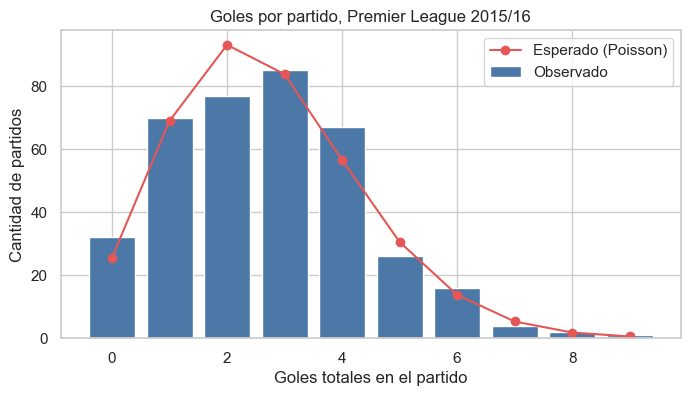

In [13]:
obs = df.goles_total.value_counts().sort_index()
k = np.arange(0, obs.index.max() + 1)
esperado = poisson.pmf(k, df.goles_total.mean()) * len(df)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(obs.index, obs.values, color="#4c78a8", label="Observado")
ax.plot(k, esperado, "o-", color="#e45756", label="Esperado (Poisson)")
ax.set(xlabel="Goles totales en el partido", ylabel="Cantidad de partidos",
       title="Goles por partido, Premier League 2015/16")
ax.legend()
plt.show()

**Qué vemos.** El promedio es **2,70 goles por partido** y la mediana 3, con una distribución casi simétrica (asimetría 0,5) y una cola hacia la derecha. La varianza (2,84) es muy parecida al promedio, que es lo que caracteriza a una Poisson, y las barras siguen bien la curva. Hay diferencias de detalle: hubo más partidos sin goles de los esperados (32 contra 25,5) y menos con 2 goles (77 contra 93). Con 380 partidos no alcanza para decir que son sistemáticas, pero queda anotado como algo a revisar si se quisiera modelar.

### Variable categórica: el resultado

In [14]:
res = df.resultado.value_counts()
pd.DataFrame({"partidos": res, "porcentaje": (res / len(df) * 100).round(1)})

,partidos,porcentaje
resultado,,
Local,157,41.3
Visitante,116,30.5
Empate,107,28.2


**Qué vemos.** El **41,3 %** de los partidos los ganó el local, el **28,2 %** terminó en empate y el **30,5 %** lo ganó el visitante. Ninguno de los tres resultados domina: casi un tercio de los partidos termina a favor del visitante.

## Paso 7. Análisis bivariado

**Qué hacemos.** Ahora cruzamos variables para buscar relaciones. Elegimos el tipo de gráfico según los tipos de variables: numérica contra categórica (comparar grupos) y numérica contra numérica (dispersión y correlación).

### Ventaja de local (numérica por categórica)

In [15]:
resumen = pd.DataFrame({
    "goles a favor por partido": t.groupby("condicion").gf.mean(),
    "puntos por partido": t.groupby("condicion").puntos.mean(),
}).round(2)
resumen

,goles a favor por partido,puntos por partido
condicion,,
Local,1.49,1.52
Visitante,1.21,1.20


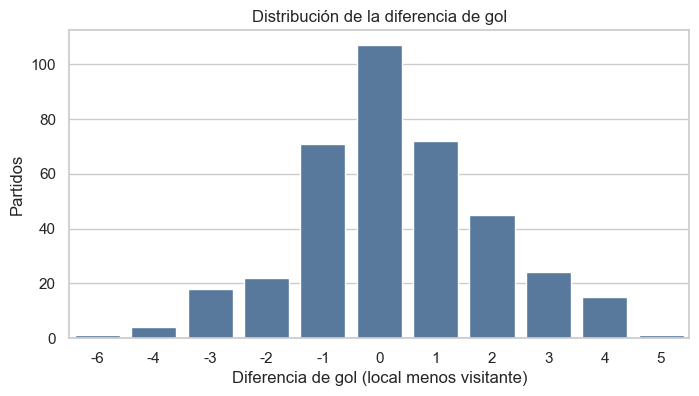

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
orden = sorted(df.dif.unique())
sns.countplot(x="dif", data=df, order=orden, color="#4c78a8", ax=ax)
ax.set(xlabel="Diferencia de gol (local menos visitante)", ylabel="Partidos",
       title="Distribución de la diferencia de gol")
plt.show()

**Qué vemos.** Hay ventaja de local, como esperábamos: **1,49 goles contra 1,21** por partido y **1,52 puntos contra 1,20**. Es una ventaja de unos 0,3 goles por partido. El gráfico muestra que la diferencia más frecuente es el empate (107 partidos), seguido de victorias por un gol de cada lado (72 del local y 71 del visitante). La asimetría aparece en las ventajas amplias: el local ganó por 2 o más goles en 85 partidos y el visitante en 45.

### Diferencia de gol y puntos (numérica contra numérica)

Nuestra hipótesis era que la diferencia de gol explica casi toda la tabla. La medimos con la **correlación de Pearson** y ajustamos una recta. Recordá que la correlación resume una relación lineal y que cada punto es un equipo (n = 20).

Correlación DG-Pts: 0.961 | R² = 0.923
Cada gol de diferencia equivale a 0.65 puntos en promedio


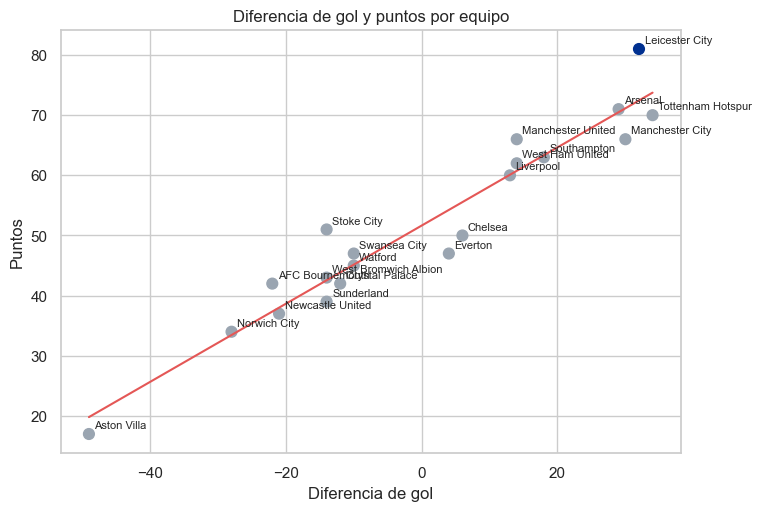

In [17]:
r = tabla["DG"].corr(tabla["Pts"])
pend, ordenada = np.polyfit(tabla["DG"], tabla["Pts"], 1)
print(f"Correlación DG-Pts: {r:.3f} | R² = {r**2:.3f}")
print(f"Cada gol de diferencia equivale a {pend:.2f} puntos en promedio")

fig, ax = plt.subplots(figsize=(8, 5.5))
colores = ["#003090" if e == "Leicester City" else "#9aa5b1" for e in tabla.equipo]
ax.scatter(tabla.DG, tabla.Pts, c=colores, s=60)
xs = np.linspace(tabla.DG.min(), tabla.DG.max(), 50)
ax.plot(xs, pend * xs + ordenada, color="#e45756", lw=1.5)
for _, f in tabla.iterrows():
    ax.annotate(f.equipo, (f.DG, f.Pts), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="Diferencia de gol", ylabel="Puntos", title="Diferencia de gol y puntos por equipo")
plt.show()

**Qué vemos.** La correlación entre diferencia de gol y puntos es **0,96** (R² = 0,92): la diferencia de gol explica el 92 % de la variación de los puntos entre equipos, y cada gol de diferencia vale 0,65 puntos. Eso confirma la hipótesis. Lo interesante son los equipos que se apartan de la recta. Tottenham tuvo la mejor diferencia de gol de la liga (+34) y terminó con 70 puntos, 11 menos que el Leicester con +32. Manchester City y Manchester United terminaron igualados en 66 puntos con diferencias muy distintas (+30 y +14). Y recordá que son 20 puntos: es una relación entre equipos, no entre partidos.

## Paso 8. Evolución en el tiempo

**Qué hacemos.** Una temporada es una serie ordenada. Miramos si los goles cambian a lo largo del calendario y cómo se fue armando la carrera por el título. Para esto ordenamos cada equipo por fecha y acumulamos puntos.

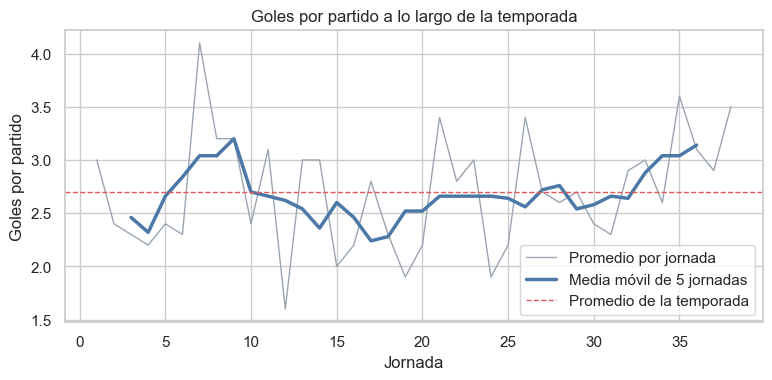

In [18]:
por_jornada = df.groupby("jornada").goles_total.mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(por_jornada.index, por_jornada.values, color="#9aa5b1", lw=1, label="Promedio por jornada")
ax.plot(por_jornada.index, por_jornada.rolling(5, center=True).mean(), color="#4c78a8", lw=2.5, label="Media móvil de 5 jornadas")
ax.axhline(df.goles_total.mean(), color="#e45756", ls="--", lw=1, label="Promedio de la temporada")
ax.set(xlabel="Jornada", ylabel="Goles por partido", title="Goles por partido a lo largo de la temporada")
ax.legend()
plt.show()

**Qué vemos.** Los goles por partido oscilan alrededor del promedio de la temporada sin una tendencia clara: 2,68 en las primeras 12 jornadas, 2,52 en las 13 siguientes y 2,90 en las últimas 13. La media móvil se mueve pero dentro de una banda angosta, lo que es esperable con solo 10 partidos por jornada.

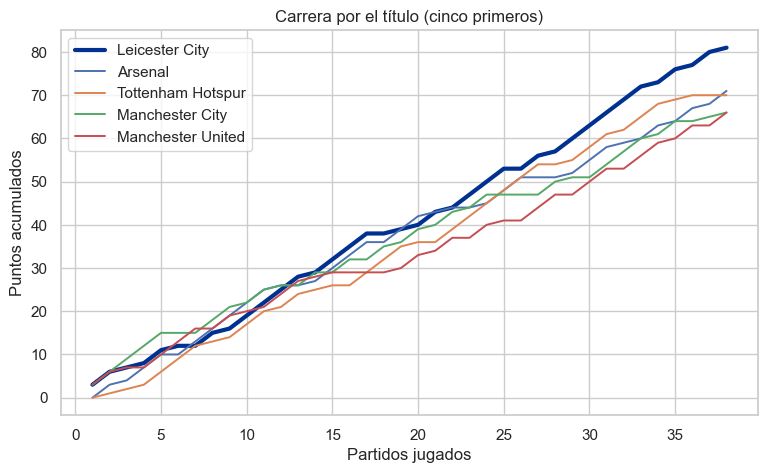

In [19]:
t = t.sort_values(["equipo", "fecha"]).reset_index(drop=True)
t["n_partido"] = t.groupby("equipo").cumcount() + 1
t["pts_acum"] = t.groupby("equipo").puntos.cumsum()

top = tabla.equipo.head(5).tolist()
fig, ax = plt.subplots(figsize=(9, 5))
for e in top:
    d = t[t.equipo == e]
    ax.plot(d.n_partido, d.pts_acum, lw=3 if e == "Leicester City" else 1.4,
            color="#003090" if e == "Leicester City" else None, label=e)
ax.set(xlabel="Partidos jugados", ylabel="Puntos acumulados", title="Carrera por el título (cinco primeros)")
ax.legend()
plt.show()

**Qué vemos.** La carrera no fue de punta a punta. Tras 10 partidos, Manchester City y Arsenal lideraban con 22 puntos. A los 19 partidos el Leicester ya estaba arriba, igualado con Arsenal con 39. A los 28 sumaba 57, tres más que Tottenham, y terminó con 81, diez más que Arsenal. El tramo final es el que define la ventaja, y el gráfico permite ver cuándo se separó del grupo.

## Paso 9. Casos atípicos

**Qué hacemos.** Un atípico no es necesariamente un error: puede ser el dato más interesante. Para decidirlo primero lo detectamos con una regla (rango intercuartil) y después lo miramos uno por uno.

La regla: un valor es atípico si supera **Q3 + 1,5 × IQR**.

In [20]:
q1, q3 = df.goles_total.quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
print(f"Q1={q1}, Q3={q3}, límite superior={limite}")
atip = df[df.goles_total > limite].sort_values("goles_total", ascending=False)
print(f"Partidos con más de {limite:g} goles: {len(atip)}")
atip[["fecha", "jornada", "local", "goles_local", "goles_visitante", "visitante", "goles_total"]]

Q1=1.0, Q3=4.0, límite superior=8.5
Partidos con más de 8.5 goles: 1


,fecha,jornada,local,goles_local,goles_visitante,visitante,goles_total
371,2016-01-23,23,Norwich City,4,5,Liverpool,9


In [21]:
df.assign(dif_abs=df.dif.abs()).nlargest(6, "dif_abs")[
    ["fecha", "local", "goles_local", "goles_visitante", "visitante", "dif"]]

,fecha,local,goles_local,goles_visitante,visitante,dif
301,2016-02-14,Aston Villa,0,6,Liverpool,-6
61,2015-10-03,Manchester City,6,1,Newcastle United,5
6,2015-12-26,Southampton,4,0,Arsenal,4
13,2016-05-15,Arsenal,4,0,Aston Villa,4
72,2015-11-01,Everton,6,2,Sunderland,4
84,2015-10-18,Newcastle United,6,2,Norwich City,4


**Qué vemos.** Solo un partido supera el límite de 8,5 goles: el **Norwich 4–5 Liverpool** (9 goles, jornada 23). La mayor diferencia fue el **Aston Villa 0–6 Liverpool**, seguida por Manchester City 6–1 Newcastle. Ninguno parece un error de carga; los verificamos como resultados reales. Conviene dejarlos en el análisis y no recortar la base, porque son parte de la distribución. Algo parecido pasa con el Aston Villa en la tabla: 3 victorias y 17 puntos, con diferencia de gol −49, muy por debajo del resto.

## Paso 10. Un nivel más fino: los eventos de los partidos del Leicester

**Qué hacemos.** El marcador resume 90 minutos en un número. Para saber si el Leicester ganó "bien" necesitamos mirar *cómo* se jugó: tiros, calidad de las ocasiones y posesión del balón. Los **eventos** (cada pase, tiro, presión) dan ese detalle.

Descargar los 380 partidos serían más de 1 GB, así que cargamos solo los **38 del Leicester** (unos 110 MB, una sola vez). Es una decisión de alcance consciente: de ahora en adelante hablamos de un equipo, no de la liga.

Para no llenar la memoria, de cada partido nos quedamos con las columnas que vamos a usar.

In [22]:
L = "Leicester City"
ids_lei = t[t.equipo == L].match_id.tolist()
print("Partidos del Leicester:", len(ids_lei))

USAR = ["id", "match_id", "type.name", "team.name", "player.name", "period", "minute",
        "location", "shot.statsbomb_xg", "shot.outcome.name", "shot.type.name"]

def cargar_eventos(mid):
    ev = pd.json_normalize(get_json(f"events/{mid}.json"))
    ev["match_id"] = mid
    return ev.reindex(columns=USAR)

with ThreadPoolExecutor(6) as ex:
    ev = pd.concat(ex.map(cargar_eventos, ids_lei), ignore_index=True)

print("Eventos:", ev.shape)
ev["type.name"].value_counts().head(8)

Partidos del Leicester: 38


Eventos: (126916, 11)


type.name
Pass             35551
Ball Receipt*    32085
Carry            25425
Pressure         11516
Ball Recovery     4139
Duel              3665
Clearance         2432
Block             1659
Name: count, dtype: int64

**Qué vemos.** Cargamos **126.916 eventos** de 38 partidos (unos 3.300 por partido). El pase es el evento más frecuente (35.551), seguido de la recepción de pelota y la conducción. Las columnas de tiro (`shot.statsbomb_xg`, `shot.outcome.name`) están vacías en todo evento que no sea un tiro: es de nuevo un vacío estructural, no un dato faltante.

### Crear variables por partido

De la tabla de eventos pasamos a **una fila por partido** con indicadores del Leicester y de su rival: tiros, goles esperados (xG) y porcentaje de pases (una aproximación a la posesión). El **xG** es la probabilidad estimada de que un tiro sea gol, según su ubicación y contexto. Sumado, dice cuántos goles "merecía" un equipo por las ocasiones que generó.

In [23]:
tiros = ev[(ev["type.name"] == "Shot") & (ev.period < 5)].copy()     # sin tandas de penales
tiros["es_lei"] = tiros["team.name"] == L

f = (tiros.groupby(["match_id", "es_lei"])
          .agg(tiros=("id", "size"), xg=("shot.statsbomb_xg", "sum"))
          .unstack("es_lei").fillna(0))
f.columns = [f"{a}_{'lei' if b else 'rival'}" for a, b in f.columns]

pases = ev[ev["type.name"] == "Pass"].copy()
pases["es_lei"] = pases["team.name"] == L
p = pases.groupby(["match_id", "es_lei"]).size().unstack()
f["pct_pases"] = p[True] / (p[True] + p[False])

partidos_lei = (t[t.equipo == L].set_index("match_id")[["fecha", "jornada", "rival", "condicion", "gf", "gc", "puntos"]]
                .join(f))
partidos_lei["dxg"] = partidos_lei.xg_lei - partidos_lei.xg_rival
partidos_lei.round(2).head()

,fecha,jornada,rival,condicion,gf,gc,puntos,tiros_rival,tiros_lei,xg_rival,xg_lei,pct_pases,dxg
match_id,,,,,,,,,,,,,
3754237,2015-08-08,1,Sunderland,Local,4,2,3,9,19,1.37,2.26,0.44,0.89
3754203,2015-08-15,2,West Ham United,Visitante,2,1,3,9,10,0.81,1.22,0.30,0.41
3753987,2015-08-22,3,Tottenham Hotspur,Local,1,1,1,19,13,1.97,0.63,0.36,-1.34
3754023,2015-08-29,4,AFC Bournemouth,Visitante,1,1,1,4,3,0.30,0.83,0.44,0.53
3754106,2015-09-13,5,Aston Villa,Local,3,2,3,11,21,1.22,1.50,0.48,0.28


In [24]:
partidos_lei[["tiros_lei", "tiros_rival", "xg_lei", "xg_rival", "pct_pases", "gf", "gc"]].describe().round(2)

,tiros_lei,tiros_rival,xg_lei,xg_rival,pct_pases,gf,gc
count,38.00,38.00,38.00,38.00,38.00,38.00,38.00
mean,13.82,13.61,1.74,1.21,0.43,1.79,0.95
std,5.76,5.66,0.87,0.67,0.08,1.04,1.04
min,3.00,3.00,0.44,0.15,0.29,0.00,0.00
25%,10.00,10.00,1.15,0.79,0.36,1.00,0.00
50%,13.00,12.00,1.60,1.12,0.43,2.00,1.00
75%,16.00,17.75,2.22,1.63,0.47,2.75,1.75
max,32.00,26.00,4.44,3.28,0.63,4.00,5.00


### ¿Goles de más? Goles reales contra goles esperados

gf          68.0
xg_lei      66.3
gc          36.0
xg_rival    46.1
Correlación gol real - xG por partido: 0.48


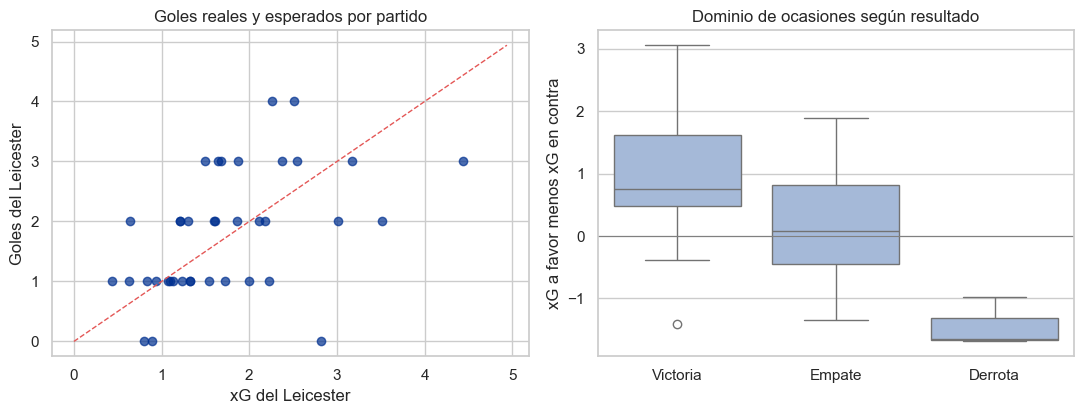

In [25]:
tot = partidos_lei[["gf", "xg_lei", "gc", "xg_rival"]].sum().round(1)
print(tot.to_string())
print("Correlación gol real - xG por partido:", round(partidos_lei.gf.corr(partidos_lei.xg_lei), 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
lim = max(partidos_lei.gf.max(), partidos_lei.xg_lei.max()) + 0.5
ax[0].scatter(partidos_lei.xg_lei, partidos_lei.gf, color="#003090", alpha=.7)
ax[0].plot([0, lim], [0, lim], color="#e45756", ls="--", lw=1)
ax[0].set(xlabel="xG del Leicester", ylabel="Goles del Leicester", title="Goles reales y esperados por partido")
res_lei = partidos_lei.puntos.map({3: "Victoria", 1: "Empate", 0: "Derrota"})
sns.boxplot(x=res_lei, y=partidos_lei.dxg, order=["Victoria", "Empate", "Derrota"], color="#9db7e0", ax=ax[1])
ax[1].set(xlabel="", ylabel="xG a favor menos xG en contra", title="Dominio de ocasiones según resultado")
ax[1].axhline(0, color="gray", lw=.8)
plt.tight_layout()
plt.show()

**Qué vemos.** **Ataque:** el Leicester marcó 68 goles y su xG fue 66,3, es decir, rindió casi exactamente lo esperado. **Defensa:** recibió 36 goles con 46,1 de xG en contra, **10 goles menos de los esperados**. La diferencia de rendimiento está en el arco propio, no en el ajeno. El gráfico de la izquierda muestra una relación débil por partido (correlación 0,48): un partido aislado se decide por pocos tiros y el azar pesa mucho. En el de la derecha, las victorias tienen una diferencia de xG mediana de +0,75 y las derrotas de −1,65 (apenas 3 partidos).

### Estilo de juego: ¿dominaron la pelota?

Porcentaje de pases promedio del Leicester: 42.6 %
Partidos con más pases que el rival: 6 de 38

puntos
0    35.5
1    44.1
3    42.7
Name: % pases promedio por puntos obtenidos, dtype: float64


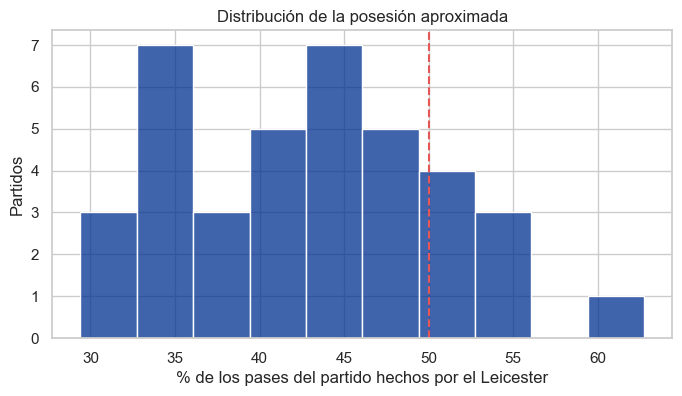

In [26]:
print("Porcentaje de pases promedio del Leicester:", round(partidos_lei.pct_pases.mean() * 100, 1), "%")
print("Partidos con más pases que el rival:", int((partidos_lei.pct_pases > .5).sum()), "de", len(partidos_lei))
print()
print(partidos_lei.groupby("puntos").pct_pases.mean().mul(100).round(1).rename("% pases promedio por puntos obtenidos"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(partidos_lei.pct_pases * 100, bins=10, color="#003090", ax=ax)
ax.axvline(50, color="#e45756", ls="--")
ax.set(xlabel="% de los pases del partido hechos por el Leicester", ylabel="Partidos", title="Distribución de la posesión aproximada")
plt.show()

**Qué vemos.** El Leicester hizo en promedio el **42,6 %** de los pases de sus partidos, y solo en **6 de 38** tuvo más pases que el rival. Ganó 23 partidos jugando casi siempre con menos la pelota, lo que es compatible con un estilo de contraataque. Cuidado con la lectura de la tabla por puntos: las derrotas son solo 3 partidos (y tuvieron el menor porcentaje de pases, 35,5 %), así que ese promedio es poco confiable. Además, el porcentaje de pases es una **aproximación** de la posesión, no la posesión medida.

### Quién metió los goles

In [27]:
goles = tiros[tiros.es_lei & (tiros["shot.outcome.name"] == "Goal")]
top_gol = (goles.groupby("player.name")
                .agg(goles=("id", "size"), de_penal=("shot.type.name", lambda s: (s == "Penalty").sum()), xg=("shot.statsbomb_xg", "sum"))
                .sort_values("goles", ascending=False).round(1).head(6))
top_gol

,goles,de_penal,xg
player.name,,,
Jamie Vardy,24,5,9.2
Riyad Mahrez,17,4,5.9
José Leonardo Ulloa,6,1,3.3
Shinji Okazaki,5,0,2.3
Robert Huth,3,0,0.2
Andrew Philip King,2,0,0.4


**Qué vemos.** Jamie Vardy hizo 24 goles (cinco de penal) y Riyad Mahrez 17 (cuatro de penal). Entre los dos suman 41 de los 68 goles del equipo. Vardy superó su xG de 9,2 por mucho, algo que en un jugador solo es difícil de separar de la suerte o de una definición excepcional, y los datos de una temporada no lo permiten distinguir.

### Dónde tiraron

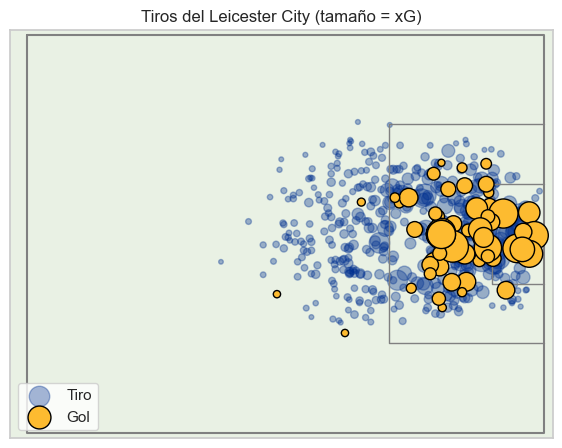

In [28]:
xy = pd.DataFrame(tiros[tiros.es_lei]["location"].tolist(), index=tiros[tiros.es_lei].index, columns=["x", "y"])
mapa = tiros[tiros.es_lei].join(xy)
mapa["gol"] = mapa["shot.outcome.name"] == "Goal"

fig, ax = plt.subplots(figsize=(7, 5.3))
ax.set_facecolor("#e9f1e4")
ax.plot([60, 120, 120, 60, 60], [0, 0, 80, 80, 0], color="gray", lw=1.5)
ax.plot([102, 102, 120], [18, 62, 62], color="gray", lw=1); ax.plot([102, 120], [18, 18], color="gray", lw=1)
ax.plot([114, 114, 120], [30, 50, 50], color="gray", lw=1); ax.plot([114, 120], [30, 30], color="gray", lw=1)
no = mapa[~mapa.gol]; si = mapa[mapa.gol]
ax.scatter(no.x, no.y, s=no["shot.statsbomb_xg"] * 500 + 8, color="#003090", alpha=.35, label="Tiro")
ax.scatter(si.x, si.y, s=si["shot.statsbomb_xg"] * 500 + 20, color="#fdbb30", edgecolor="black", label="Gol", zorder=3)
ax.set(xlim=(58, 121), ylim=(81, -1), title="Tiros del Leicester City (tamaño = xG)")
ax.set_xticks([]); ax.set_yticks([]); ax.legend(loc="lower left")
plt.show()

**Qué vemos.** De los 525 tiros del Leicester, el **64 %** salió desde dentro del área grande, y 64 de sus 67 goles con tiro salieron de ahí (el otro gol del equipo fue un gol en contra del rival). El xG promedio por tiro fue 0,13. El mapa muestra que las ocasiones más valiosas, las burbujas más grandes, se concentran cerca del arco.

## Paso 11. Conclusiones y límites

**Qué hacemos.** Cerramos el EDA volviendo a las preguntas del Paso 1 y separando tres cosas: lo que los datos **muestran**, lo que **sugieren** y lo que **no permiten** afirmar. Un buen EDA termina con preguntas más afinadas, no solo con respuestas.

Volvemos a las tres preguntas del Paso 1.

**1. ¿Cómo es una temporada típica?** Promedia 2,7 goles por partido, con una distribución que se ajusta bien a una Poisson. El local gana el 41 % de los partidos, empata el 28 % y pierde el 31 %. La ventaja de local es real pero moderada: unos 0,3 goles por partido.

**2. ¿Qué separa a los de arriba de los de abajo?** La diferencia de gol explica el 92 % de la variación de puntos entre equipos (r = 0,96). Los atípicos de la recta (Tottenham y Manchester United) son los puntos para investigar. El Aston Villa, con 17 puntos y −49, es un caso extremo que merece análisis aparte.

**3. ¿El Leicester ganó por rendimiento sostenido o por suerte?** Los datos muestran que su ataque rindió lo que decían sus ocasiones (68 goles con 66,3 de xG) y que su defensa recibió 10 goles menos que los esperados (36 con 46,1). También muestran que casi siempre tuvo menos la pelota que su rival (42,6 % de los pases). **Sugieren** que la ventaja sobre el resto vino en buena parte de una defensa que rindió por encima de lo esperado, lo que puede deberse a la calidad del arco propio, a la forma de defender o al azar, y los datos de este notebook **no permiten separar** esas tres explicaciones.

### Lo que no podemos afirmar

- **Un solo equipo en el nivel fino.** Cargamos eventos solo del Leicester. Sin los demás equipos no sabemos si recibir menos goles que el xG fue excepcional o habitual en la liga.
- **El xG es un modelo.** Depende de cómo se construyó y no es una observación directa.
- **Una temporada, 20 equipos.** La correlación de 0,96 está calculada con 20 puntos; no justifica hablar de una ley del fútbol.
- **Descriptivo, no causal.** Que el Leicester tuviera poca posesión y ganara no demuestra que la poca posesión cause victorias.

### Próximos pasos

Cargar los eventos de los 20 equipos para comparar el rendimiento contra el xG de toda la liga, medir la posesión real con los eventos de posesión y probar un modelo de Poisson para predecir resultados.

## Checklist de un EDA

Una lista para aplicar a cualquier base nueva:

- [ ] Escribí la pregunta y las hipótesis **antes** de mirar.
- [ ] Identificá la **unidad de análisis** (qué representa una fila) y cuántas hay.
- [ ] Revisá **tipos** de columna y convertí fechas y categorías.
- [ ] Buscá **nulos, duplicados e imposibles**; distinguí vacío estructural de dato perdido.
- [ ] **Validá** contra una fuente externa o una regla del dominio.
- [ ] Creá variables derivadas con reglas claras; cambiá de unidad de análisis si hace falta.
- [ ] **Univariado:** centro, dispersión y forma de cada variable.
- [ ] **Bivariado:** el gráfico depende del tipo de variables; mirá antes de correlacionar.
- [ ] **Tiempo:** ¿hay tendencias, estacionalidad, quiebres?
- [ ] **Atípicos:** detectalos con una regla y decidí uno por uno si son error o información.
- [ ] Anotá el **alcance**: qué población cubren los datos y qué decisiones de recorte tomaste.
- [ ] Concluí separando lo que se **muestra**, lo que se **sugiere** y lo que **no se puede afirmar**.

## Ejercicios para la clase

1. Repetí el Paso 6 con `goles_local` y `goles_visitante` por separado. ¿Cuál se parece más a una Poisson?
2. En el Paso 7, calculá la correlación entre **GF** y puntos y entre **GC** y puntos. ¿Se gana más por atacar o por defender?
3. Cargá los eventos de otro equipo (por ejemplo el campeón de otra temporada disponible) y compará su `pct_pases` con el del Leicester.
4. Calculá cuántos puntos habría sumado cada equipo si todos los partidos hubieran terminado como lo indica el xG. ¿Cambia el campeón?